# 01 · San Francisco stats for the slides

**Slide 8 claim: our data can answer our question.** This notebook covers the first half:
*the vibe is in the reviews.* There are enough SF places with enough reviews, reviewers describe
the atmosphere and not only the food, and Google's own tags give us a way to check results.
(The second half, *but not in the words people search with*, is notebook 02.)

Every number here is written to `reports/numbers.md`.

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd

from vibecheck.filter_sf import REVIEWS_OUT, load_places
from vibecheck.lexicon import VIBE_WORDS, term_pattern
from vibecheck.plots import GROUP_COLORS, MUTED, SINGLE_COLOR, use_style
from vibecheck.report import write_section

use_style()
places = load_places()
reviews = pd.read_parquet(REVIEWS_OUT)

## 1. Headline counts

In [2]:
per_place = reviews.groupby("gmap_id").size()
headline = {
    "SF cafes, restaurants and bars": len(places),
    "...with at least one review with text": per_place.size,
    "Reviews kept (max 50 per place)": len(reviews),
    "Median reviews kept per place": int(per_place.median()),
    "Places at the 50-review cap": int((per_place == 50).sum()),
    "Median Google review count per place": int(places["num_of_reviews"].median()),
    "Median review length (words)": int(reviews["text"].str.split().str.len().median()),
}
headline_df = pd.DataFrame(headline.items(), columns=["metric", "value"])
headline_df.style.format({"value": "{:,}"}).hide(axis="index")

metric,value
"SF cafes, restaurants and bars","5,679"
...with at least one review with text,"5,669"
Reviews kept (max 50 per place),"212,176"
Median reviews kept per place,48
Places at the 50-review cap,"2,413"
Median Google review count per place,118
Median review length (words),15


## 2. Category breakdown

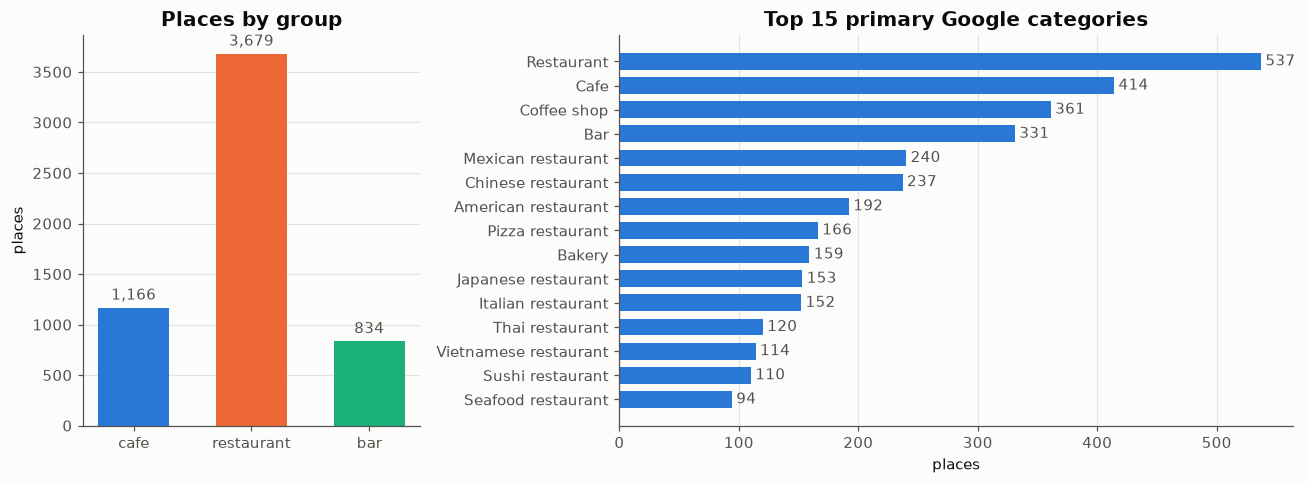

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1, 2]})

groups = places["group"].value_counts().reindex(GROUP_COLORS)
ax1.bar(groups.index, groups.values, color=list(GROUP_COLORS.values()), width=0.6)
ax1.bar_label(ax1.containers[0], fmt="{:,.0f}", padding=3, color=MUTED)
ax1.set(title="Places by group", ylabel="places")
ax1.grid(axis="x", visible=False)

top = places["category"].map(lambda cats: cats[0]).value_counts().head(15).sort_values()
ax2.barh(top.index, top.values, color=SINGLE_COLOR, height=0.7)
ax2.bar_label(ax2.containers[0], padding=3, color=MUTED)
ax2.set(title="Top 15 primary Google categories", xlabel="places")
ax2.grid(axis="y", visible=False)

plt.tight_layout()
fig.savefig("../reports/category_breakdown.png")
plt.show()

## 3. Google's MISC tags

`MISC` is a dict of tag groups. The interesting one for us is **Atmosphere**
(Casual / Cozy / Trendy / Upscale ...). It is Google's own label for the vibe, so we can use it
to check whether search results make sense. **Popular for** ("Good for working on laptop")
and **Crowd** are useful too.

In [4]:
key_counts = Counter(key for misc in places["misc"] for key in misc)
misc_df = pd.DataFrame(key_counts.most_common(), columns=["MISC key", "places"])
misc_df["% of places"] = (100 * misc_df["places"] / len(places)).round(1)
misc_df

,MISC key,places,% of places
0,Service options,5313,93.6
1,Offerings,4564,80.4
2,Accessibility,4178,73.6
3,Amenities,3713,65.4
4,Atmosphere,3654,64.3
5,Dining options,3333,58.7
6,Payments,3094,54.5
7,Popular for,2970,52.3
8,Crowd,2922,51.5
9,Highlights,2319,40.8


In [5]:
def tag_counts(key: str) -> pd.DataFrame:
    """How many places carry each value of one MISC tag group."""
    counts = Counter(value for misc in places["misc"] for value in misc.get(key, []))
    return pd.DataFrame(counts.most_common(), columns=[key, "places"])

for key in ["Atmosphere", "Popular for", "Crowd"]:
    display(tag_counts(key))

,Atmosphere,places
0,Casual,3475
1,Cozy,1862
2,Romantic,248
3,Upscale,235
4,Historic,82
5,Trending,36
6,Quiet,18


,Popular for,places
0,Solo dining,2781
1,Lunch,2292
2,Dinner,2103
3,Breakfast,709
4,Good for working on laptop,299


,Crowd,places
0,Groups,1944
1,Tourists,1311
2,Family-friendly,889
3,College students,711
4,Locals,86
5,Family friendly,17
6,University students,16


## 4. Do reviewers talk about the vibe?

Share of reviews that use at least one plain atmosphere word (list in `lexicon.VIBE_WORDS`).

12.9% of reviews mention the atmosphere
83.0% of places have at least one such review


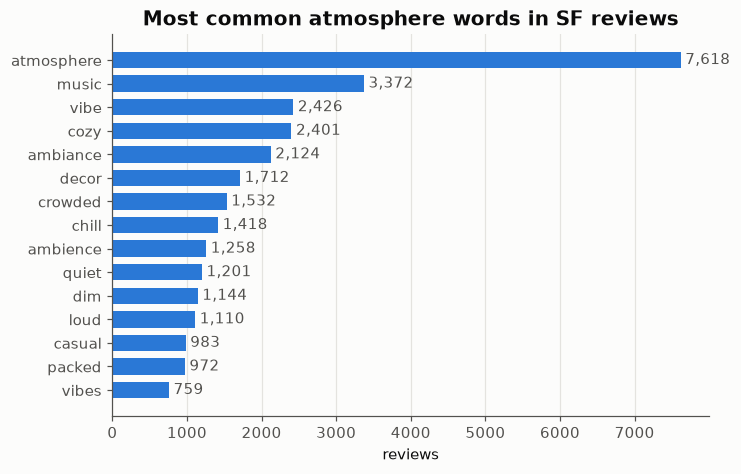

In [6]:
mentions_vibe = reviews["text"].str.contains(term_pattern(VIBE_WORDS))
places_with_vibe = reviews.loc[mentions_vibe, "gmap_id"].nunique()
print(f"{mentions_vibe.mean():.1%} of reviews mention the atmosphere")
print(f"{places_with_vibe / per_place.size:.1%} of places have at least one such review")

word_counts = pd.Series({w: reviews["text"].str.contains(term_pattern([w])).sum() for w in VIBE_WORDS})
word_counts = word_counts.sort_values().tail(15)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(word_counts.index, word_counts.values, color=SINGLE_COLOR, height=0.7)
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3, color=MUTED)
ax.set(title="Most common atmosphere words in SF reviews", xlabel="reviews")
ax.grid(axis="y", visible=False)
fig.savefig("../reports/vibe_words.png")
plt.show()

## 5. Do Google's Atmosphere tags agree with the review text?

If places tagged *Cozy* are much more likely to have a review saying "cozy", the tags are a fair
check for search results. We compare tagged and untagged places for each tag.

In [7]:
# Which review words count as "saying" a tag. Default: the tag itself, lowercased.
TAG_WORDS = {"Cozy": ["cozy", "cosy"], "Trending": ["trending", "trendy"]}

place_text = reviews.groupby("gmap_id")["text"].agg(" ".join)
rows = []
for tag, n in tag_counts("Atmosphere").itertuples(index=False):
    tagged = places.loc[[tag in m.get("Atmosphere", []) for m in places["misc"]], "gmap_id"]
    says_it = place_text.str.contains(term_pattern(TAG_WORDS.get(tag, [tag.lower()])))
    in_tagged = says_it.index.isin(tagged)
    rows.append({"Atmosphere tag": tag, "places tagged": n,
                 "% tagged places whose reviews say it": round(100 * says_it[in_tagged].mean(), 1),
                 "% untagged places whose reviews say it": round(100 * says_it[~in_tagged].mean(), 1)})
agreement = pd.DataFrame(rows)
agreement

,Atmosphere tag,places tagged,% tagged places whose reviews say it,% untagged places whose reviews say it
0,Casual,3475,14.2,14.0
1,Cozy,1862,42.6,19.0
2,Romantic,248,25.8,3.0
3,Upscale,235,21.3,3.9
4,Historic,82,20.7,1.4
5,Trending,36,8.3,4.7
6,Quiet,18,27.8,16.3


## 6. One real example for a slide

The most-reviewed *Cozy* cafe with at least two short reviews that mention the atmosphere.

In [8]:
# Short reviews (40-250 chars) that mention the vibe make the best slide quotes.
quotable = reviews[reviews["text"].str.len().between(40, 250) & reviews["text"].str.contains(term_pattern(VIBE_WORDS))]
n_quotes = quotable.groupby("gmap_id").size()
cozy_cafes = places[places["misc"].map(lambda m: "Cozy" in m.get("Atmosphere", [])) & (places["group"] == "cafe")]
candidates = cozy_cafes[cozy_cafes["gmap_id"].map(n_quotes).fillna(0) >= 2]
example = candidates.sort_values("num_of_reviews", ascending=False).iloc[0].copy()
example["address"] = example["address"].removeprefix(f"{example['name']}, ")  # address repeats the name
for field in ["name", "address", "category", "avg_rating", "num_of_reviews", "price"]:
    print(f"{field:>15}: {example[field]}")
print(f"{'Atmosphere':>15}: {example['misc'].get('Atmosphere')}")
print(f"{'Popular for':>15}: {example['misc'].get('Popular for')}")

ex_reviews = quotable[quotable["gmap_id"] == example["gmap_id"]].head(2)
for r in ex_reviews.itertuples():
    print(f"\n★{r.rating}  \"{r.text}\"")

           name: Four Barrel Coffee
        address: 375 Valencia St, San Francisco, CA 94103
       category: ['Coffee shop']
     avg_rating: 4.5
 num_of_reviews: 2187
          price: $$
     Atmosphere: ['Casual', 'Cozy']
    Popular for: ['Solo dining', 'Good for working on laptop']

★5.0  "Great coffee in the Mission with comfortable seating and a carefully curated vibe!"

★5.0  "Still my favorite!
Great coffee, great vibe‼️"


## 7. Write to `reports/numbers.md`

In [9]:
atmos = tag_counts("Atmosphere")
md = f"""## Data: the vibe is in the reviews (notebook 01)

{headline_df.to_markdown(index=False, intfmt=",")}

- Groups: {", ".join(f"{g} {n:,}" for g, n in groups.items())}
- **{mentions_vibe.mean():.1%} of reviews** use a plain atmosphere word; **{places_with_vibe / per_place.size:.1%} of places** have at least one such review.
- {key_counts["Atmosphere"]:,} places ({key_counts["Atmosphere"] / len(places):.0%}) have Google's *Atmosphere* tag: {", ".join(f"{t} {n:,}" for t, n in atmos.itertuples(index=False))}.

Tag vs. review text (are Google's tags a fair check?):

{agreement.to_markdown(index=False)}

Example place: **{example["name"]}**, {example["address"]} · {example["category"][0]} · ★{example["avg_rating"]} ({example["num_of_reviews"]:,} Google reviews) · Atmosphere: {", ".join(example["misc"].get("Atmosphere", []))}

{chr(10).join(f'> ★{r.rating:.0f} "{" ".join(r.text.split())}"' for r in ex_reviews.itertuples())}
"""
write_section("data", md)
print(md)

## Data: the vibe is in the reviews (notebook 01)

| metric                                |   value |
|:--------------------------------------|--------:|
| SF cafes, restaurants and bars        |   5,679 |
| ...with at least one review with text |   5,669 |
| Reviews kept (max 50 per place)       | 212,176 |
| Median reviews kept per place         |      48 |
| Places at the 50-review cap           |   2,413 |
| Median Google review count per place  |     118 |
| Median review length (words)          |      15 |

- Groups: cafe 1,166, restaurant 3,679, bar 834
- **12.9% of reviews** use a plain atmosphere word; **83.0% of places** have at least one such review.
- 3,654 places (64%) have Google's *Atmosphere* tag: Casual 3,475, Cozy 1,862, Romantic 248, Upscale 235, Historic 82, Trending 36, Quiet 18.

Tag vs. review text (are Google's tags a fair check?):

| Atmosphere tag   |   places tagged |   % tagged places whose reviews say it |   % untagged places whose reviews say it |
|:-----